# Rock vs Metal

This Jupyter Notebook is inspired in the following papers [Analysis of Hidden Units in a Layered Network
Trained to Classify Sonar Targets](http://citeseerx.ist.psu.edu/viewdoc/download?doi=10.1.1.84.6963&rep=rep1&type=pdf) and [Learned Classification of Sonar Targets Using a
Massively Parallel Network](https://citeseerx.ist.psu.edu/viewdoc/download?doi=10.1.1.164.2513&rep=rep1&type=pdf) by Paul Gorman and Terrence Sejnowski. In order to complete this project, I highly recommend that you read both papers to fully understand the problems that you will later solve.

## Part 1: Create a reflected FM chirp signal
A chirp is a signal in which the frequency increases (up-chirp) or decreases (down-chirp) with time. It is commonly applied to sonar, radar, and laser systems, and to other applications, such as in spread-spectrum communications.

In spread-spectrum usage, surface acoustic wave (SAW) devices are often used to generate and demodulate the chirped signals. In optics, ultrashort laser pulses also exhibit chirp, which, in optical transmission systems, interacts with the dispersion properties of the materials, increasing or decreasing total pulse dispersion as the signal propagates. The name is a reference to the chirping sound made by birds. 

In this part two task are described:
1. How to create a linear FM swept-frequency cosine chirp signal?
2. How to model the received sonar signal? 

### 1. Mathematical description of the chirp signal
This signal is defined as follows:

$$x(t)=\cos{\left( \phi(t) + \rho \right)}$$

where $\phi(t)$ is the instantaneous phase of the signal given by

$$\phi(t)=\int_{0}^{t} 2\pi f(t) dt$$

and $f(t)$ as
$$f(t) = f_0 + \frac{(f_1-f_0)t}{t_1}$$

where $t_1$ is the chirp's duration, $f_0$ is the initial frequency, and $f_1$ is the frequency at time $t_1$.

### 2. Mathematical model of the received chirp signal
We can model our received sonar chirp signal $\hat{x}(t)$ as modified version of the original signal $x(t)$ as follows:

suppose we have a transmitted signal

$$x(t)=\cos{\left( \phi(t) + \rho \right)}$$

Which has been affected by three main sources of distortion:
1. additive white noise $n(t)$,
2. propagation effect, modeled as an exponential decay,
3. random time delay $\tau$ at the receiving end

then we can formulate an equation as follows

$$\hat{x}(t)=e^{t}x(t-\tau)+n(t)$$

that describes the received signal.

### Create your python functions
In this part you will implement the following two functions:
1. `chirp` which is a function that returns a chirp signal like the one described in **Mathematical description of the chirp signal**
2. `noisy_chirp` which is a function that returns a signal like the one described in **Mathematical model of the received chirp signal**

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pickle
import pandas as pd
from scipy.signal import chirp as scipy_chirp
from scipy import signal
from sklearn.linear_model import RidgeClassifier

First create your `chirp` function. For this task, you will also create a function `get_phase` which calculates the phase needed for the `chirp` signal.

In [2]:
def get_phase(t, f0, f1, t1):
    """
    Auxiliary function that performs the calculation of the phase of a linear instantaneous frequency.
    :param t: (numpy vector) defines the time at which we evaluate the waveform
    :param f0: (float) frequency in Hz. at time t=0.
    :param f1: (float) frequency in Hz. of the waveform at time t1.
    :param t1: (float) time at which f1 is specified
    :return: phase calculation of the linear instantaneous phase
    """
    # Implement the instantaneous phase φ(t) of a linear signal f(t)
    ### BEGIN SOLUTION
    return 2*np.pi*(f0*t + 0.5*(f1-f0)*np.square(t)/t1)
    ### END SOLUTION


def chirp(t, f0, f1, t1, phi=0):
    """
    Function that calculates an FM chirp signal.
    :param t: (numpy vector) defines the time at which we evaluate the waveform
    :param f0: (float) frequency in Hz. at time t=0.
    :param f1: (float) frequency in Hz. of the waveform at time t1.
    :param t1: (float) time at which f1 is specified
    :param phi: (float, optional) Phase offset, in degrees. Default is 0.
    :return: (numpy array) chirp FM signal
    """
    # Implement the chirp signal x(t) described before
    ### BEGIN SOLUTION
    phase = get_phase(t, f0, f1, t1)
    return np.cos(phase + np.pi*phi/180)
    ### END SOLUTION

Now test your implementation against the SciPy implementation of the chirp signal. If your results match, then everything is working perfectly!

Your test and reference signals are same. Gret work!


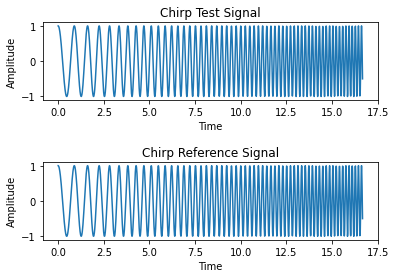

In [3]:
f0 = 1
f1 = 6
t1 = 100*(1/f1)
t = np.linspace(0, t1, 1500)

signal_test = chirp(t, f0, f1, t1)
signal_reference = scipy_chirp(t, f0=f0, f1=f1, t1=t1, method='linear')

match = np.allclose(signal_test, signal_reference)

if match:
    print("Your test and reference signals are same. Gret work!")
else:
    print("Your test and reference signals differ.")

plt.subplot(2,1,1)
plt.plot(t, signal_test)
plt.title("Chirp Test Signal")
plt.xlabel("Time")
plt.ylabel("Amplitude")

plt.subplot(2,1,2)
plt.plot(t, signal_reference)
plt.title("Chirp Reference Signal")
plt.xlabel("Time")
plt.ylabel("Amplitude")

plt.subplots_adjust(hspace=0.8)

assert match, "Check your code! Your implementation has some errors!"

Now make your noisy chirp signal. For this task you will create the `noisy_chirp` function, remember that the function performs the following calculation:

$$\hat{x}(t)=e^{t}x(t-\tau)+n(t)$$

Bear in mind that $\tau$ introduces an offset to the signal, and at the end of the signal there's also a trailing data received. The following image can explain this idea:

![Received](Images/received_signal.png)

In order to define your `noisy_chirp` you will have to perform three steps:
1. Create a `transmitted` vector that will implement this equation $e^{t}x(t)$.
2. Add a header `tau`, a `trail` to the transmitted data. This will simulate the effect of having an offset on the received signal. We will use random values between `50` and `60` for the size of `tau` and `trail`. You can assign the size by using the numpy function `random.randint` to generate random numbers. 
3. Add noise to the new vector created in step 2, this will simulate the effect of additive noise to the offset signal. Assume noise as a random process with mean zero and standard deviation of `0.2`.

In [4]:
def noisy_chirp(x, t):
    """
    Function that calculates a noisy FM chirp signal. Assume 
    :param x: (numpy vector) input chirp signal
    :param t: (numpy vector) defines the time at which we evaluate the waveform
    :return: (numpy array) noisy chirp FM signal
    """
    np.random.seed(123) #Set this to have the same results.
    # Step 1:
    # Create your transmitted vector
    ### BEGIN SOLUTION
    transmitted = (np.exp(-t) * x).reshape(-1, 1)
    ### END SOLUTION
    
    # Step 2:
    # Create frame with tau, trail and transmitted
    ### BEGIN SOLUTION
    tau = np.random.randint(50, 60)
    trail = np.random.randint(50, 60)
    
    N = tau + trail + x.shape[0]
    y = np.zeros((N, 1))
    
    y[tau:-trail] = transmitted
    ### END SOLUTION
    
    # Step 3:
    # Add noise to the received frame
    ### BEGIN SOLUTION
    mu, sigma = 0, 0.20 # mean and standard deviation
    noise = np.random.normal(mu, sigma, (y.shape[0], 1))   
    
    y += noise
    return y
    ### END SOLUTION

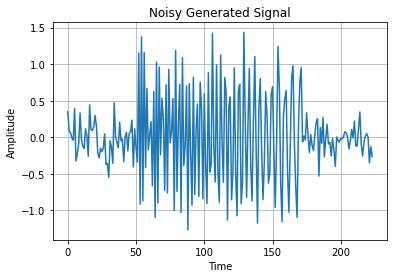

In [5]:
with open('chirp_received.pkl', 'rb') as file:
    received_pkl = pickle.load(file)

f0 = 13000
f1 = 21000
t1 = 100*(1/f1)
t = np.linspace(0, t1, 120)

transmitted = chirp(t, f0, f1, t1)
received = noisy_chirp(transmitted, t)

assert np.allclose(received, received_pkl, atol=0.01)

plt.plot(received)
plt.title("Noisy Generated Signal")
plt.ylabel("Amplitude")
plt.xlabel("Time")
plt.grid('on')
plt.show()

## Part 2: Find the power spectral density
Right now our problem is that we want to estimate the power spectral density of a wide-sense stationary random process. The main problem of power spectrum estimation is that data $x[n]$ is always finite. There are two basic approaches to solve this problem:
1. Nonparametric such as *Periodogram*, *Bartlett* and *Welch* (most common)
2. Parametric approaches (less common)

For our implementation we will use Bartlett's method, if you want further information about other methods you can check this [link](http://www.laurent-duval.eu/Documents-Common/Schuster_G_2010_lect_spectrum_upbw.pdf).

Bartlett’s method consists of the following steps:

1. The original N point data segment is split up into K (non-overlapping) data segments, each of length M
2. For each segment, compute the periodogram by the use of the discrete Fourier transform, then compute the squared magnitude of the result and divide this by M.
3. Average the result of the periodograms above for the K data segments. (The averaging reduces the variance, compared to the original N point data segment.)

The end result is an array of power measurements vs. frequency "bin".

In [6]:
def bartlett_periodogram(x, nperseg, fs=1.0):
    """
    Estimate power spectral density using Bartlett’s method.
    :param x: (numpy vector) input signal
    :param nperseg: (int) length of each segment of data
    :param fs: (float) sampling frequency of the x time series. Defaults to 1.0.
    :return: freq (numpy vector) normalized frequency values between 0 and 0.5 for psd calculation
             psd (numpy vector) power spectral density using Bartlett’s method
    """
    N = x.shape[0]
    nsegments = N // nperseg
    psd = np.zeros(nperseg)
    # Split data into K non-overlapping segments
    ### BEGIN SOLUTION
    data_split = x.reshape(nsegments, nperseg)
    ### END SOLUTION
    for segment in data_split:
        # Use the Fourier Transform on each segment
        # Square the magnitude of the Fourier Transform
        # Divide by the segment data size
        ### BEGIN SOLUTION
        dft = np.fft.fft(segment)
        psd += np.square(np.abs(dft.reshape(-1,)))/ nperseg
        ### END SOLUTION

    psd[0] = 0   # important!!
    # Average the psd by the number of data segments
    ### BEGIN SOLUTION
    psd /= nsegments
    ### END SOLUTION
    psd = psd[0: nperseg // 2] #Removes two sided spectrum
    freq = np.linspace(0, fs/2, nperseg//2)
    freq /= 2*freq[-1]

    return freq, psd #Be cautious to always set psd[0]=0
    

def fix_size(x, N=64):
    """
    Auxiliary function to give a power of two dimension to input x
    :param x: (numpy vector) input signal
    :param N: (int) minimum size input x should have
    :return: (numpy vector) vector x with size(x)%N zeros appended
    """
    zeros = x.shape[0] % N
    if zeros>0:
        temp = np.zeros((N-zeros, 1))
    return np.append(x, temp)


Now it is time to test your `bartlett_periodogram` implementation, for this purpose you will compare it with the `signal.welch` from SciPy. The `signal.welch` implementation performs the Welch's method for estimating the spectral density of a signal, since Welch's method is an upgrade version of Bartlett's, we can get the same results for both methods by setting the overlap for Welch's method to zero. You can get more information about Welch's method [here](https://en.wikipedia.org/wiki/Welch%27s_method). Note that Welch returns the power spectral density, which is the power spectrum times $f_s$ and it compensates for cutting away half the spectrum by multiplying with $2$. To compensate, we multiply Bartlett's method by $2f_s$ in order to compare with Welch.
Check your results, and if the plots match, then everything works well!

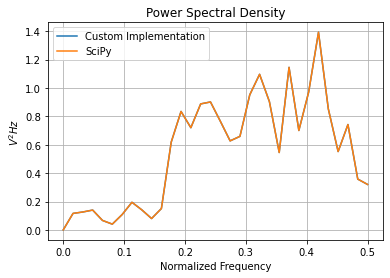

In [7]:
nperseg = 64
fs = 1

f_bartlett, psd_bartlett = bartlett_periodogram(fix_size(received), nperseg=nperseg)

f_welch, psd_welch = signal.welch(fix_size(received), fs=fs, nperseg=nperseg, 
                                nfft=nperseg, window='boxcar', noverlap=0)

assert np.allclose(2*fs*psd_bartlett, psd_welch[:-1], atol=0.01)

f = f_bartlett

plt.plot(f, 2*fs*psd_bartlett, label="Custom Implementation")
plt.plot(f, psd_welch[:-1], label="SciPy") 
plt.title("Power Spectral Density")
plt.xlabel("Normalized Frequency")
plt.ylabel("$V^2Hz$")
plt.grid('on')
plt.legend()
plt.show()

## Part 3: Create a classifier using a linear regression model
In this final part you will implement a linear regression classifier for the [**Connectionist Bench (Sonar, Mines vs. Rocks) Data Set**](http://archive.ics.uci.edu/ml/datasets/connectionist+bench+(sonar,+mines+vs.+rocks)). This dataset is the same used in the papers described at the beginning of this Jupyter Notebook. To simplify our task we are going to use Pandas, which is a data analysis and manipulation library for Python.

First we load our dataset which is called `dataset_sonar.csv` and it is stored in the `Dataset` folder. We also defined a function called `get_data` whose purpose is to simplify our data retrieval.

In [8]:
file = "Dataset/dataset_sonar.csv"
data = pd.read_csv(file)

def get_data(data, k):
    x = data.iloc[k][0:-1]
    y = data.iloc[k][-1]
    return x, y

Here you can see how our data looks and how different a signal from a Rock and Mine is received.

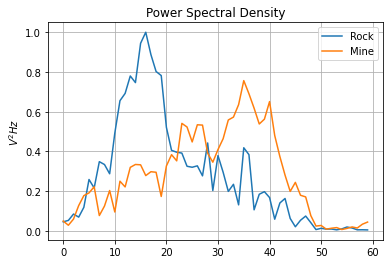

In [9]:
x0, y0 = get_data(data, k=1)
x1, y1 = get_data(data, k=97)
t = np.arange(x0.shape[0])

plt.plot(t, x0, label=y0)
plt.plot(t, x1, label=y1)
plt.title("Power Spectral Density")
plt.ylabel("$V^2Hz$")
plt.grid('on')
plt.legend()
plt.show()

A linear regression model can be described as

$$\hat{y} = w_0 + w_1x_1 + w_2x_2 + \cdots w_nx_n $$

In vector form we can have
$$\hat{y} = Xw $$

where $X$ has a column vector of ones in the first entry.

The following Python code shows a function called `linear_regression` which is an implementation of a linear regression model. Note that we stack a column of ones to take into account the bias vector $w_0$ from the model.

In [10]:
def linear_regression(X, w):
    """
    Function that calculates a the linear regression model of X and w. 
    :param X: (numpy matrix) matrix with of features in columns and observations in rows.
    :param w: (numpy vector) linear regression coefficients.
    :return: (numpy vector) calculation of y = Xw
    """
    
    n = X.shape[0]
    ones = np.ones(n)
    X = np.column_stack([ones, X])
    
    return np.dot(X,w)

When we want to find a solution for the equation 

$$\hat{y} = Xw $$

Usually, this solution is not exact, and instead an approximation using a least squares solution is proposed.

We can use the following expession to obtain an approximate estimation of the $w$ coeffcients:
$$ y \approx Xw$$
$$ X^Ty \approx X^TXw$$
$$ (X^TX)^{-1}X^Ty \approx (X^TX)^{-1}(X^TX)w$$
$$ (X^TX)^{-1}X^Ty \approx w$$

Where $X^TX$ is called the Gram Matrix


We can get better results if we introduce a regularization factor, which reduces the linear relationship between columns, by changing the  in Gram Matrix in the following way:

Instead of using a matrix $$X^TX = \begin{bmatrix}
x_{11} & x_{12} & x_{13} & \cdots & x_{1n} \\
x_{21} & x_{22} & x_{23} & \cdots & x_{2n} \\
x_{31} & x_{32} & x_{33} & \cdots & x_{3n} \\
\vdots & \vdots & \vdots & \vdots & \vdots \\
x_{n1} & x_{n2} & x_{n3} & \cdots & x_{nn}
\end{bmatrix}  $$

We use this matrix $$X^TX + \alpha I = \begin{bmatrix}
x_{11}+\alpha & x_{12} & x_{13} & \cdots & x_{1n} \\
x_{21} & x_{22}+\alpha & x_{23} & \cdots & x_{2n} \\
x_{31} & x_{32} & x_{33}+\alpha & \cdots & x_{3n} \\
\vdots & \vdots & \vdots & \vdots & \vdots \\
x_{n1} & x_{n2} & x_{n3} & \cdots & x_{nn}+\alpha
\end{bmatrix}  $$

Therefore, our final equation will be

$$ (X^TX + \alpha I)^{-1}X^Ty \approx w$$


Create a function called `train_linear_regression` wich takes as input a matrix `X` of features, a vector `y` of labels and a regularization factor `r`. This function trains a linear regression model using the equation described before. You can use the `np.dot` funtion to multiply two matrices. 

In [11]:
def train_linear_regression(X, y, r=1):
    """
    Function that estimates the linear regression coefficients using a least squares solution. 
    :param X: (numpy matrix) matrix with of features in columns and observations in rows.
    :param y: (numpy vector) expected values.
    :return: (numpy vector) estimated w coefficients
    """
    n = X.shape[0]
    ones = np.ones(n)
    # Add an extra column to X to add the bias term of the linear regression
    ### BEGIN SOLUTION
    X = np.column_stack([ones, X])
    ### END SOLUTION
    
    # Implement the equation for approximating the w values 
    ### BEGIN SOLUTION
    XTX = np.dot(X.T, X)
    
    #Regularization
    XTX = XTX + r*np.eye(XTX.shape[0])
    
    XTX_inv = np.linalg.inv(XTX)
    return np.dot(np.dot(XTX_inv, X.T),y)
    ### END SOLUTION

In this test you will see if your `train_linear_regression` function works correctly. Your expected mean squared error should be around `0.0009`.

In [12]:
X = np.array([[1, -1, 2], [-3, -5, 4], [6, -7, -8]])
y = np.array([[ -7], [-27], [ 22]])

w_hat = train_linear_regression(X, y, r=0.1)

y_hat = linear_regression(X, w_hat)

mse = np.mean((y - y_hat)**2)

with open('y_hat.pkl', 'rb') as file:
    y_hat_pkl = pickle.load(file)
    
assert np.allclose(y_hat, y_hat_pkl, atol=0.01)

print(f'Exected value = \n {y} \n \n Predicted value = \n {y_hat} \n')
print(f'MSE = {mse:.4f}')

Exected value = 
 [[ -7]
 [-27]
 [ 22]] 
 
 Predicted value = 
 [[ -6.97271844]
 [-26.95582226]
 [ 21.98982713]] 

MSE = 0.0009


Now that you've created your linear model, and tested that correctly estimates the coefficients,  we can use it to classify our data into rock and metal. Usually we split all of our data into three groups:
* Training data: used for training the model
* Validation data: used for selecting best parameters
* Test data: used for evaluating the performance of the model

For this task, a `split_data` function is provided, where you include a pandas dataframe as input `df`, and set the proportion of data used for validation `val_proportion`, and the data used for testing `test_proportion`. A good rule of thumb is to use a `0.20` proportion for both validation and test data.

In [13]:
def split_data(df, val_proportion=0.30, test_proportion=0.30, random_seed=True):
    """
    Auxiliary function to split data into training, validation and test data.
    :param df: (pandas dataframe) dataframe with features to train the model.
    :param val_proportion: (float) value between 0 and 1 to set the proportion of validation data.
    :param test_proportion: (float) value between 0 and 1 to set the proportion of test data.
    :return: (tuple) tumple containing df_train, df_val, df_test dataframes
    
    """
    if random_seed:
        np.random.seed(2)
        
    n = len(df)
    n_val = int(n * val_proportion)
    n_test = int(n * test_proportion)
    n_train = n - (n_val + n_test)

    # Create a list of indices and shuffle them
    idx = np.arange(n)
    np.random.shuffle(idx)

    # Sample from the shuffled indices
    N_train = idx[:n_train]
    N_val = idx[n_train:n_train + n_val]
    N_test = idx[n_train + n_val:]
    len(N_train), len(N_val), len(N_test)

    df_train = df.iloc[N_train]
    df_val = df.iloc[N_val]
    df_test = df.iloc[N_test]
    
    # Reset the index of every dataframe
    df_train = df_train.reset_index(drop=True)
    df_val = df_val.reset_index(drop=True)
    df_test = df_test.reset_index(drop=True)
    
    return df_train, df_val, df_test

In [14]:
# Set val_p and test_p to the typical values used as rule of thumb.
### BEGIN SOLUTION
val_p = 0.20
test_p = 0.20
### END SOLUTION
df_train, df_val, df_test = split_data(data, val_proportion=val_p, test_proportion=test_p, random_seed=True)

In [15]:
assert df_train.shape == (126, 61)
assert df_val.shape == (41, 61)
assert df_test.shape == (41, 61)

Since we are not going to select the best parameters for our model, we will merge the training and validation data into a full data set called `df_full_train`. Therefore, we will be using a training and test set for our model.

In [16]:
# Create a full training set
df_full_train = pd.concat([df_train, df_val]).reset_index(drop=True)

# Training Data
X_full_train = df_full_train.iloc[: , :-1].values
Y_full_train = (df_full_train.iloc[:, -1] == 'Rock').astype('int')

# Test Data
X_test = df_test.iloc[: , :-1].values
Y_test = (df_test.iloc[:, -1] == 'Rock').astype('int')

In [17]:
# Use your linear regression model to estimate the vector W
### BEGIN SOLUTION
W = train_linear_regression(X_full_train, Y_full_train)
### END SOLUTION

# Predict y_hat the linear_regression function 
### BEGIN SOLUTION
Y_hat = linear_regression(X_test, W)
### END SOLUTION


In [18]:
accuracy = sum((Y_hat>0.50).astype('int') == Y_test)/Y_test.shape[0]

# Compare against the RidgeClassifier from Scikit-learn
clf = RidgeClassifier()
clf.fit(X_full_train, Y_full_train)

accuracy_ridge_classifier = sum(clf.predict(X_test) == Y_test)/Y_test.shape[0]

assert np.isclose(accuracy, accuracy_ridge_classifier, atol=0.001)

## Part 4: Questions
* Why do we use the power spectral density in our linear classifier instead of the time domain signal?
* What does regularization mean, and why do we use it in our linear classifier?

Add your answer here...